# Face inversion: analysis

Loads the trained checkpoints from Drive and runs the analyses (tuning curves, layer-wise tests, RDM similarity, statistics). Only the test faces are needed, unless you also train the second seed (last two cells).

The outputs below come from a run after the seed 1 models were trained, so every number is averaged over 2 seeds.

In [ ]:
# escnn is needed to rebuild the equivariant model
!pip -q install git+https://github.com/AMLab-Amsterdam/lie_learn
!pip -q install escnn
import torch
print('torch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - switch runtime to T4')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
torch 2.14.1+cu130 | GPU: Tesla T4


In [ ]:
# mount drive, unpack only the test faces
import os, time
from google.colab import drive; drive.mount('/content/drive')
ROOTD = '/content/drive/MyDrive/face_inversion'
print(sorted(os.listdir(ROOTD))); print(sorted(os.listdir(f'{ROOTD}/ckpt')))
t0 = time.time()
if not os.path.isdir('/content/vggface2_aligned/test'):
    !tar -xf {ROOTD}/vggface2_aligned112.tar -C /content vggface2_aligned/test
print(f'test faces ready ({time.time() - t0:.0f} s)')

Mounted at /content/drive
['analysis', 'ckpt', 'figures', 'gai_by_layer.csv', 'holistic_results.csv', 'split.json', 'vggface2_aligned112.tar', 'vggface2_subset.tar']
['augmented.pt', 'augmented_s1.pt', 'baseline.pt', 'baseline_s1.pt', 'equivariant.pt', 'equivariant_s1.pt']
test faces ready (47 s)


In [ ]:
# same preprocessing and model definitions as the training notebook
import glob, json, itertools, random, numpy as np, pandas as pd, cv2, torchvision
import torch.nn.functional as F, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score
from escnn import gspaces, nn as enn

CKPT = f'{ROOTD}/ckpt'
ids = json.load(open(f'{ROOTD}/split.json'))['ids']  # 500 training identities, sets the classifier size

MEAN = torch.tensor([0.485, 0.456, 0.406], device='cuda').view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device='cuda').view(1, 3, 1, 1) * 255
yy, xx = torch.meshgrid(torch.arange(112, device='cuda'), torch.arange(112, device='cuda'), indexing='ij')
MASK = (((yy - 55.5) ** 2 + (xx - 55.5) ** 2) <= 56 ** 2).float().view(1, 1, 112, 112)  # used for every model

def rotate(x, deg):  # per-sample rotation about the centre
    t = torch.deg2rad(deg); c, s, z = torch.cos(t), torch.sin(t), torch.zeros_like(t)
    theta = torch.stack([torch.stack([c, -s, z], 1), torch.stack([s, c, z], 1)], 1)
    return F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), align_corners=False)

def prep(xu8, mode, train):
    x = xu8.float()
    if train:
        flip = torch.rand(len(x), device='cuda') < 0.5
        x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
        if mode == 'augmented':
            x = rotate(x, torch.rand(len(x), device='cuda') * 360)
    return ((x - MEAN) / STD * MASK).contiguous(memory_format=torch.channels_last)

G = gspaces.rot2dOnR2(N=4)
rtype = lambda n: enn.FieldType(G, n * [G.regular_repr])
MaxPool = getattr(enn, 'PointwiseMaxPool2D', None) or enn.PointwiseMaxPool
EQ_SIZE = 97  # odd size at every stride-2 stage so rot90 equivariance is exact

class EqBlock(torch.nn.Module):
    def __init__(s, tin, tout, stride):
        super().__init__()
        s.c1, s.b1, s.r1 = enn.R2Conv(tin, tout, 3, stride=stride, padding=1, bias=False), enn.InnerBatchNorm(tout), enn.ReLU(tout, inplace=True)
        s.c2, s.b2 = enn.R2Conv(tout, tout, 3, padding=1, bias=False), enn.InnerBatchNorm(tout)
        s.sc = None if (stride == 1 and tin == tout) else enn.SequentialModule(
            enn.R2Conv(tin, tout, 1, stride=stride, bias=False), enn.InnerBatchNorm(tout))
        s.r2 = enn.ReLU(tout, inplace=True)
    def forward(s, x):
        y = s.b2(s.c2(s.r1(s.b1(s.c1(x)))))
        return s.r2(y + (x if s.sc is None else s.sc(x)))

class C4ResNet18(torch.nn.Module):
    def __init__(s, n_classes, widths=(32, 64, 128, 256)):
        super().__init__()
        s.tin = enn.FieldType(G, 3 * [G.trivial_repr]); t = rtype(widths[0])
        s.stem = enn.SequentialModule(enn.R2Conv(s.tin, t, 7, stride=2, padding=3, bias=False),
                                      enn.InnerBatchNorm(t), enn.ReLU(t, inplace=True),
                                      MaxPool(t, kernel_size=3, stride=2, padding=1))
        blocks, tp = [], t
        for i, w in enumerate(widths):
            for j in range(2):
                blocks.append(EqBlock(tp, rtype(w), 2 if (i > 0 and j == 0) else 1)); tp = rtype(w)
        s.blocks = torch.nn.Sequential(*blocks)
        s.gpool = enn.GroupPooling(tp)
        s.fc = torch.nn.Linear(widths[-1], n_classes)
    def forward(s, x):
        x = F.interpolate(x.float(), size=EQ_SIZE, mode='bilinear', align_corners=False)
        x = s.gpool(s.blocks(s.stem(enn.GeometricTensor(x, s.tin)))).tensor
        return s.fc(x.mean((2, 3)))

def make_model(mode):
    return C4ResNet18(len(ids)) if mode == 'equivariant' else torchvision.models.resnet18(num_classes=len(ids))
print(len(ids), 'identities; definitions ready')

500 identities; definitions ready


In [ ]:
# test faces and stimuli, same seeds as the training notebook so the pairs match holistic_results.csv
class Raw(Dataset):
    def __init__(s, items): s.items = items
    def __len__(s): return len(s.items)
    def __getitem__(s, k):
        return torch.from_numpy(cv2.cvtColor(cv2.imread(s.items[k][0]), cv2.COLOR_BGR2RGB)).permute(2, 0, 1)

def to_gpu(items):
    X = torch.empty((len(items), 3, 112, 112), dtype=torch.uint8, device='cuda'); n = 0
    for x in tqdm(DataLoader(Raw(items), batch_size=1024, num_workers=os.cpu_count())):
        X[n:n + len(x)] = x.cuda(non_blocking=True); n += len(x)
    return X, torch.tensor([l for _, l in items], device='cuda')

TROOT = '/content/vggface2_aligned/test'
tids = sorted(d for d in os.listdir(TROOT) if d.startswith('n'))
rng = np.random.default_rng(1); items = []
for lab, i in enumerate(tids):
    fs = sorted(glob.glob(f'{TROOT}/{i}/*.jpg'))
    items += [(f, lab) for f in rng.choice(fs, min(10, len(fs)), replace=False)]
Xte, Yte = to_gpu(items); print('test faces', tuple(Xte.shape))

@torch.no_grad()
def embed(m, imgs, mode, bs=500):
    out = []
    for i in range(0, len(imgs), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(feats(m, prep(imgs[i:i + bs], mode, False)).float())
    return F.normalize(torch.cat(out), dim=1)

def feats(m, x):
    if isinstance(m, C4ResNet18):
        x = F.interpolate(x.float(), size=EQ_SIZE, mode='bilinear', align_corners=False)
        return m.gpool(m.blocks(m.stem(enn.GeometricTensor(x, m.tin)))).tensor.mean((2, 3))
    x = m.maxpool(m.relu(m.bn1(m.conv1(x))))
    return torch.flatten(m.avgpool(m.layer4(m.layer3(m.layer2(m.layer1(x))))), 1)

inv = lambda x: torch.rot90(x, 2, dims=(2, 3))

def thatcher(x):
    x = x.clone()
    for (cx, cy), (w, h) in [((38, 52), (26, 16)), ((74, 52), (26, 16)), ((56, 92), (40, 20))]:
        y0, x0 = cy - h // 2, cx - w // 2
        x[:, :, y0:y0 + h, x0:x0 + w] = x[:, :, y0:y0 + h, x0:x0 + w].flip(2)
    return x

SPLIT, SHIFT = 64, 32
def composite(top, bot, aligned):
    out = top.clone(); b = bot[:, :, SPLIT:]
    if not aligned: b = torch.roll(b, SHIFT, dims=3); b[..., :SHIFT] = 0
    out[:, :, SPLIT:] = b
    out[:, :, SPLIT - 1:SPLIT + 1] = 0
    return out

by_id = {}
for k, l in enumerate(Yte.tolist()): by_id.setdefault(l, []).append(k)
labs = list(by_id); NP = 3000
SP = torch.tensor([tuple(rng.choice(by_id[labs[rng.integers(len(labs))]], 2, replace=False)) for _ in range(NP)], device='cuda')
DP = torch.tensor([(rng.choice(by_id[labs[a]]), rng.choice(by_id[labs[b]]))
                   for a, b in (rng.choice(len(labs), 2, replace=False) for _ in range(NP))], device='cuda')
NC = 2000; CA, CB, CC, CD = (torch.as_tensor(rng.integers(len(Xte), size=NC), device='cuda') for _ in range(4))

LAYERS = ['stem', 'stage1', 'stage2', 'stage3', 'stage4', 'embedding']
@torch.no_grad()
def layer_acts(m, x):
    if isinstance(m, C4ResNet18):
        h = m.stem(enn.GeometricTensor(F.interpolate(x.float(), size=EQ_SIZE, mode='bilinear', align_corners=False), m.tin)); out = [h.tensor]
        for i, b in enumerate(m.blocks):
            h = b(h)
            if i % 2 == 1: out.append(h.tensor)
        return out + [m.gpool(h).tensor.mean((2, 3))]
    h = m.maxpool(m.relu(m.bn1(m.conv1(x)))); out = [h]
    for L in (m.layer1, m.layer2, m.layer3, m.layer4): h = L(h); out.append(h)
    return out + [torch.flatten(m.avgpool(h), 1)]
print('stimuli ready')

test faces (5000, 3, 112, 112)
stimuli ready


In [ ]:
# find all checkpoints (seed 0 and seed 1) and set up the bootstrap
import itertools, scipy.stats as ss
ANA = '/content/drive/MyDrive/face_inversion/analysis'; os.makedirs(ANA, exist_ok=True)
FIG = '/content/drive/MyDrive/face_inversion/figures'; os.makedirs(FIG, exist_ok=True)
MODES, COL = ['baseline', 'augmented', 'equivariant'], {'baseline': 'C0', 'augmented': 'C1', 'equivariant': 'C2'}
ckpt_path = lambda mode, seed: f'{CKPT}/{mode}.pt' if seed == 0 else f'{CKPT}/{mode}_s{seed}.pt'
RUNS = [(md, sd) for md in MODES for sd in (0, 1) if os.path.exists(ckpt_path(md, sd))]
PRESENT = [md for md in MODES if any(r[0] == md for r in RUNS)]
seeds_of = lambda mode: [s for md, s in RUNS if md == mode]
print('runs found:', RUNS)

def load_run(mode, seed):
    m = make_model(mode).cuda().to(memory_format=torch.channels_last)
    m.load_state_dict(torch.load(ckpt_path(mode, seed), map_location='cuda', weights_only=False)['model'])
    return m.eval()

def rot(deg):  # rot90 for multiples of 90, bilinear otherwise
    if deg % 90 == 0: return lambda z: torch.rot90(z, int(deg // 90) % 4, dims=(2, 3))
    return lambda z: rotate(z, torch.full((len(z),), float(deg), device='cuda'))

BOOT, _BI = 1000, {}
def boot_idx(n):  # resample positives and negatives separately, same draws for every model
    if n not in _BI:
        g = np.random.default_rng(2)
        _BI[n] = np.concatenate([g.integers(0, n, (BOOT, n)), g.integers(n, 2 * n, (BOOT, n))], 1)
    return _BI[n]

def auc_fast(S):  # first half positives, second half negatives, auc along the last axis
    n = S.shape[-1] // 2; R = ss.rankdata(S, axis=-1)
    return (R[..., :n].sum(-1) - n * (n + 1) / 2) / (n * n)

def auc_boot(s):  # auc and its bootstrap draws
    return float(auc_fast(s)), auc_fast(s[boot_idx(len(s) // 2)])

ci = lambda b: np.percentile(b, [2.5, 97.5])
pval = lambda b: float(min(1.0, 2 * min((b <= 0).mean(), (b >= 0).mean())))  # two-sided bootstrap p

PAIRS = torch.cat([SP, DP])  # 3000 same-identity pairs, then 3000 different-identity pairs
def pair_scores(m, mode, ta, tb):
    return (embed(m, ta(Xte[PAIRS[:, 0]].float()), mode) * embed(m, tb(Xte[PAIRS[:, 1]].float()), mode)).sum(1).cpu().numpy()

PT, BT = {r: {} for r in RUNS}, {r: {} for r in RUNS}  # point estimates and bootstrap draws per run

runs found: [('baseline', 0), ('baseline', 1), ('augmented', 0), ('augmented', 1), ('equivariant', 0), ('equivariant', 1)]


## Orientation tuning

done baseline seed 0
done baseline seed 1
done augmented seed 0
done augmented seed 1
done equivariant seed 0
done equivariant seed 1


,model,seed,auc_up,auc_inv,inversion_index,lo,hi
0,baseline,0,0.8499,0.6375,0.2499,0.2339,0.2664
1,baseline,1,0.8396,0.6403,0.2373,0.2199,0.2553
2,augmented,0,0.8951,0.8942,0.0009,-0.0044,0.0058
3,augmented,1,0.8943,0.8973,-0.0034,-0.0086,0.0014
4,equivariant,0,0.9025,0.9025,0.0000,-0.0000,0.0000
5,equivariant,1,0.8971,0.8971,0.0000,-0.0000,0.0000


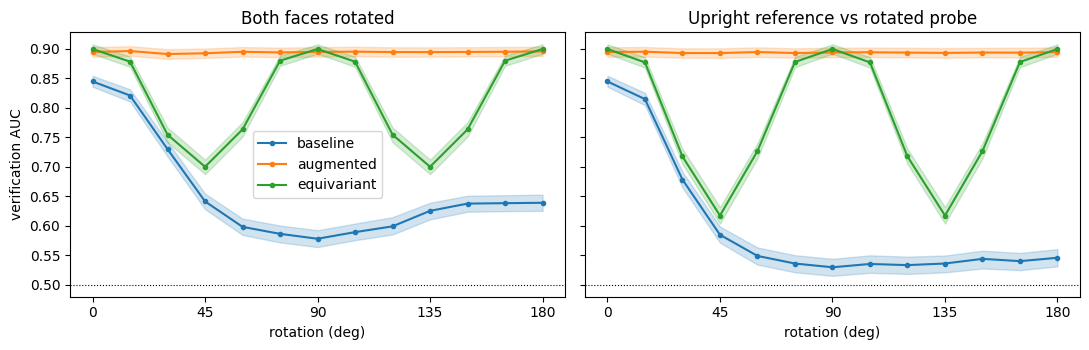

model        augmented  baseline  equivariant
cond  angle                                  
both  0          0.895     0.845        0.900
      45         0.893     0.641        0.700
      90         0.895     0.578        0.900
      135        0.894     0.625        0.700
      180        0.896     0.639        0.900
probe 0          0.895     0.845        0.900
      45         0.893     0.585        0.617
      90         0.894     0.530        0.900
      135        0.893     0.536        0.617
      180        0.895     0.546        0.900

In [ ]:
# verification auc from 0 to 180 deg with 95% bootstrap CIs
# both: both faces rotated by the same angle. probe: upright reference vs rotated probe
ANGLES = list(range(0, 181, 15))  # every 15 deg
TS, trows = {}, []
for mode, seed in RUNS:
    m = load_run(mode, seed)
    for cond in ['both', 'probe']:
        for a in ANGLES:
            s = pair_scores(m, mode, rot(a) if cond == 'both' else (lambda z: z), rot(a))
            auc, b = auc_boot(s); TS[(mode, seed, cond, a)] = (s, b)
            lo, hi = ci(b); trows.append(dict(model=mode, seed=seed, cond=cond, angle=a, auc=auc, lo=lo, hi=hi))
    del m; torch.cuda.empty_cache(); print('done', mode, 'seed', seed)
tune = pd.DataFrame(trows); tune.to_csv(f'{ANA}/tuning_curves.csv', index=False)

for r in RUNS:
    for a in (0, 45, 90, 135, 180):
        PT[r][f'auc_{a}'], BT[r][f'auc_{a}'] = float(auc_fast(TS[(*r, 'both', a)][0])), TS[(*r, 'both', a)][1]
    PT[r]['auc_probe_180'], BT[r]['auc_probe_180'] = float(auc_fast(TS[(*r, 'probe', 180)][0])), TS[(*r, 'probe', 180)][1]
    # inversion index = (upright - inverted) / upright
    PT[r]['inversion_index'] = (PT[r]['auc_0'] - PT[r]['auc_180']) / PT[r]['auc_0']
    BT[r]['inversion_index'] = (BT[r]['auc_0'] - BT[r]['auc_180']) / BT[r]['auc_0']
inv_df = pd.DataFrame([dict(model=r[0], seed=r[1], auc_up=PT[r]['auc_0'], auc_inv=PT[r]['auc_180'],
                            inversion_index=PT[r]['inversion_index'], lo=ci(BT[r]['inversion_index'])[0],
                            hi=ci(BT[r]['inversion_index'])[1]) for r in RUNS]).round(4)
inv_df.to_csv(f'{ANA}/inversion_index.csv', index=False); display(inv_df)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a_, cond in zip(ax, ['both', 'probe']):
    g = tune[tune.cond == cond].groupby(['model', 'angle'])[['auc', 'lo', 'hi']].mean().reset_index()
    for mode in PRESENT:
        d = g[g.model == mode]
        a_.plot(d.angle, d.auc, 'o-', ms=3, color=COL[mode], label=mode)
        a_.fill_between(d.angle, d.lo, d.hi, color=COL[mode], alpha=.2)
    a_.axhline(.5, color='k', lw=.8, ls=':')
    a_.set(xticks=ANGLES[::3], xlabel='rotation (deg)', title={'both': 'Both faces rotated', 'probe': 'Upright reference vs rotated probe'}[cond])
ax[0].set_ylabel('verification AUC'); ax[0].legend()
plt.tight_layout(); plt.savefig(f'{FIG}/4_tuning_curves.png', dpi=200); plt.show()
display(tune[tune.angle.isin([0, 45, 90, 135, 180])].pivot_table(index=['cond', 'angle'], columns='model', values='auc').round(3))

## Layer-wise analyses

done baseline seed 0
done baseline seed 1
done augmented seed 0
done augmented seed 1
done equivariant seed 0
done equivariant seed 1


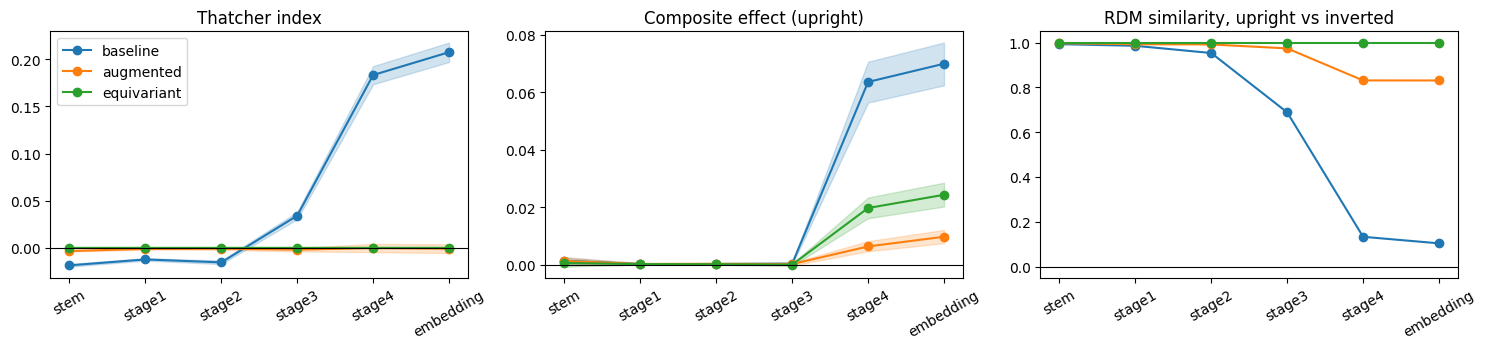

thatcher_index                      composite_effect           \
model          augmented baseline equivariant        augmented baseline   
layer                                                                     
stem              -0.003   -0.019        -0.0            0.001    0.001   
stage1            -0.001   -0.012        -0.0            0.000    0.000   
stage2            -0.001   -0.015        -0.0            0.000    0.000   
stage3            -0.002    0.034        -0.0            0.000    0.000   
stage4            -0.000    0.183        -0.0            0.006    0.064   
embedding         -0.001    0.207        -0.0            0.010    0.070   

                      composite_effect_inv                      rsa_up_vs_inv  \
model     equivariant            augmented baseline equivariant     augmented   
layer                                                                           
stem            0.001                0.001    0.002       0.001         0.997   
stage1          0.000                0.000    0.000       0.000         0.992   
stage2          0.000                0.000    0.000       0.000         0.991   
stage3         -0.000                0.000    0.000      -0.000         0.974   
stage4          0.020                0.008    0.007       0.020         0.831   
embedding       0.024                0.013    0.009       0.024         0.831   

                                
model     baseline equivariant  
layer                           
stem         0.993         1.0  
stage1       0.985         1.0  
stage2       0.953         1.0  
stage3       0.688         1.0  
stage4       0.133         1.0  
embedding    0.104         1.0

In [ ]:
# thatcher index and composite effect at every layer, and spearman correlation between the upright and inverted rdm
# for the c4 model 180 deg is an exact symmetry, so its thatcher index is 0 and rdm similarity is 1 by construction
@torch.no_grad()
def layer_sims(m, mode, A, B, bs=200):  # cosine similarity of A[i] and B[i] at each layer
    out = []
    for i in range(0, len(A), bs):
        la, lb = layer_acts(m, prep(A[i:i + bs], mode, False)), layer_acts(m, prep(B[i:i + bs], mode, False))
        out.append(torch.stack([F.cosine_similarity(x.flatten(1).float(), y.flatten(1).float(), dim=1) for x, y in zip(la, lb)]))
    return torch.cat(out, 1).cpu().numpy()

@torch.no_grad()
def layer_rdms(m, mode, X, bs=250):  # correlation-distance rdm per layer, upper triangle
    acts = None
    for i in range(0, len(X), bs):
        la = [a.flatten(1).float().cpu() for a in layer_acts(m, prep(X[i:i + bs], mode, False))]
        acts = la if acts is None else [torch.cat([p, q]) for p, q in zip(acts, la)]
    iu = np.triu_indices(len(X), 1)
    return [(1 - torch.corrcoef(a)).numpy()[iu] for a in acts]

XT = Xte[:2000].float(); NT = len(XT)
BIT = np.random.default_rng(3).integers(0, NT, (BOOT, NT))  # same bootstrap draws for every model
XR = Xte[::10].float()  # one face per test identity
lrows = []
for mode, seed in RUNS:
    m = load_run(mode, seed); r = (mode, seed)
    up = 1 - layer_sims(m, mode, XT, thatcher(XT))
    dn = 1 - layer_sims(m, mode, inv(XT), inv(thatcher(XT)))
    bu, bd = up[:, BIT].mean(2), dn[:, BIT].mean(2)
    th, bth = (up.mean(1) - dn.mean(1)) / (up.mean(1) + dn.mean(1)), (bu - bd) / (bu + bd)
    comp = {}
    for tag, f in [('', lambda z: z), ('_inv', inv)]:
        for al in (True, False):
            c1, cs, cd = (f(composite(Xte[t].float(), Xte[b_].float(), al)) for t, b_ in [(CA, CB), (CA, CC), (CD, CC)])
            S = np.concatenate([layer_sims(m, mode, c1, cs), layer_sims(m, mode, c1, cd)], 1)
            comp[(tag, al)] = (auc_fast(S), auc_fast(S[:, boot_idx(NC)]))
    rsa = [ss.spearmanr(p, q)[0] for p, q in zip(layer_rdms(m, mode, XR), layer_rdms(m, mode, inv(XR)))]
    ce = {tag: (comp[(tag, False)][0] - comp[(tag, True)][0], comp[(tag, False)][1] - comp[(tag, True)][1]) for tag in ('', '_inv')}
    for li, L in enumerate(LAYERS):
        row = dict(model=mode, seed=seed, layer=L, thatcher_index=th[li], th_lo=ci(bth[li])[0], th_hi=ci(bth[li])[1],
                   rsa_up_vs_inv=rsa[li])
        for tag in ('', '_inv'):
            row[f'composite_effect{tag}'] = ce[tag][0][li]
            row[f'ce{tag}_lo'], row[f'ce{tag}_hi'] = ci(ce[tag][1][li])
        lrows.append(row)
    PT[r].update(thatcher_index=float(th[-1]), composite_effect=float(ce[''][0][-1]), composite_effect_inv=float(ce['_inv'][0][-1]))
    BT[r].update(thatcher_index=bth[-1], composite_effect=ce[''][1][-1], composite_effect_inv=ce['_inv'][1][-1])
    del m; torch.cuda.empty_cache(); print('done', mode, 'seed', seed)

lay = pd.DataFrame(lrows); lay.to_csv(f'{ANA}/layerwise.csv', index=False)
g = lay.groupby(['model', 'layer'], sort=False).mean(numeric_only=True).reset_index()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a_, (k, lo, hi, t) in zip(ax, [('thatcher_index', 'th_lo', 'th_hi', 'Thatcher index'),
                                  ('composite_effect', 'ce_lo', 'ce_hi', 'Composite effect (upright)'),
                                  ('rsa_up_vs_inv', None, None, 'RDM similarity, upright vs inverted')]):
    for mode in PRESENT:
        d = g[g.model == mode]
        a_.plot(LAYERS, d[k], 'o-', color=COL[mode], label=mode)
        if lo: a_.fill_between(LAYERS, d[lo], d[hi], color=COL[mode], alpha=.2)
    a_.axhline(0, color='k', lw=.8); a_.set_title(t); a_.tick_params(axis='x', rotation=30)
ax[0].legend(); plt.tight_layout(); plt.savefig(f'{FIG}/5_layerwise.png', dpi=200); plt.show()
display(g.pivot(index='layer', columns='model', values=['thatcher_index', 'composite_effect', 'composite_effect_inv', 'rsa_up_vs_inv']).reindex(LAYERS).round(3))

## Statistics

In [ ]:
# summary with 95% bootstrap CIs, paired bootstrap contrasts (holm corrected),
# and a repeated measures anova (model x angle) over 20 disjoint folds of pairs
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multitest import multipletests
METRICS = ['auc_0', 'auc_45', 'auc_90', 'auc_135', 'auc_180', 'inversion_index', 'auc_probe_180',
           'thatcher_index', 'composite_effect', 'composite_effect_inv']
smean = lambda D, mode, k: np.mean([D[(mode, s)][k] for s in seeds_of(mode)], 0)

summ = []
for mode in PRESENT:
    for k in METRICS:
        lo, hi = ci(smean(BT, mode, k))
        summ.append(dict(model=mode, metric=k, value=smean(PT, mode, k), lo=lo, hi=hi,
                         per_seed=' / '.join(f'{PT[(mode, s)][k]:.3f}' for s in seeds_of(mode))))
summary = pd.DataFrame(summ); summary.to_csv(f'{ANA}/summary_with_ci.csv', index=False)
display(summary.assign(cell=summary.apply(lambda x: f'{x.value:.3f} [{x.lo:.3f}, {x.hi:.3f}]', axis=1))
        .pivot(index='metric', columns='model', values='cell').reindex(METRICS))

tests = []
for k in ['auc_0', 'auc_45', 'inversion_index', 'thatcher_index', 'composite_effect', 'composite_effect_inv']:
    for a, b in itertools.combinations(PRESENT, 2):
        d = smean(BT, a, k) - smean(BT, b, k)
        tests.append(dict(metric=k, contrast=f'{a} - {b}', diff=smean(PT, a, k) - smean(PT, b, k), lo=ci(d)[0], hi=ci(d)[1], p=pval(d)))
tests = pd.DataFrame(tests); tests['p_holm'] = multipletests(tests.p, method='holm')[1]
tests.to_csv(f'{ANA}/model_contrasts.csv', index=False); display(tests.round(4))

K = 20; gfold = np.random.default_rng(4)
fpos, fneg = gfold.permutation(NP) % K, gfold.permutation(NP) % K  # 150 same and 150 different pairs per fold
arows = []
for mode in PRESENT:
    for a in (0, 45, 90, 135, 180):
        for k in range(K):
            aucs = [roc_auc_score(np.r_[np.ones((fpos == k).sum()), np.zeros((fneg == k).sum())],
                                  np.r_[TS[(mode, s, 'both', a)][0][:NP][fpos == k], TS[(mode, s, 'both', a)][0][NP:][fneg == k]])
                    for s in seeds_of(mode)]
            arows.append(dict(model=mode, angle=a, fold=k, auc=np.mean(aucs)))
adf = pd.DataFrame(arows); adf.to_csv(f'{ANA}/anova_folds.csv', index=False)
aov = AnovaRM(adf, depvar='auc', subject='fold', within=['model', 'angle']).fit()
print(aov); aov.anova_table.to_csv(f'{ANA}/anova_model_x_orientation.csv')
print('Saved to', ANA)

model,augmented,baseline,equivariant
metric,,,
auc_0,"0.895 [0.887, 0.902]","0.845 [0.837, 0.853]","0.900 [0.893, 0.907]"
auc_45,"0.893 [0.885, 0.900]","0.641 [0.630, 0.652]","0.700 [0.689, 0.710]"
auc_90,"0.895 [0.888, 0.902]","0.578 [0.566, 0.590]","0.900 [0.893, 0.907]"
auc_135,"0.894 [0.887, 0.902]","0.625 [0.613, 0.637]","0.700 [0.689, 0.710]"
auc_180,"0.896 [0.889, 0.903]","0.639 [0.627, 0.651]","0.900 [0.893, 0.907]"
inversion_index,"-0.001 [-0.005, 0.002]","0.244 [0.229, 0.257]","0.000 [-0.000, 0.000]"
auc_probe_180,"0.895 [0.887, 0.902]","0.546 [0.534, 0.558]","0.900 [0.893, 0.907]"
thatcher_index,"-0.001 [-0.004, 0.003]","0.207 [0.198, 0.216]","-0.000 [-0.000, 0.000]"
composite_effect,"0.010 [0.008, 0.012]","0.070 [0.063, 0.076]","0.024 [0.021, 0.028]"


,metric,contrast,diff,lo,hi,p,p_holm
0,auc_0,baseline - augmented,-0.0499,-0.0582,-0.0414,0.000,0.000
1,auc_0,baseline - equivariant,-0.0551,-0.0619,-0.0484,0.000,0.000
2,auc_0,augmented - equivariant,-0.0051,-0.0113,0.0010,0.122,0.366
3,auc_45,baseline - augmented,-0.2512,-0.2632,-0.2398,0.000,0.000
4,auc_45,baseline - equivariant,-0.0588,-0.0712,-0.0470,0.000,0.000
5,auc_45,augmented - equivariant,0.1925,0.1813,0.2041,0.000,0.000
6,inversion_index,baseline - augmented,0.2448,0.2304,0.2586,0.000,0.000
7,inversion_index,baseline - equivariant,0.2436,0.2293,0.2568,0.000,0.000
8,inversion_index,augmented - equivariant,-0.0012,-0.0050,0.0022,0.532,1.000
9,thatcher_index,baseline - augmented,0.2084,0.1987,0.2175,0.000,0.000


                   Anova
             F Value  Num DF  Den DF  Pr > F
--------------------------------------------
model       1941.3129 2.0000  38.0000 0.0000
angle        798.5315 4.0000  76.0000 0.0000
model:angle  494.6352 8.0000 152.0000 0.0000

Saved to /content/drive/MyDrive/face_inversion/analysis


## Second seed

Trains every model again with seed 1 and the same settings (about 2.2 h on a T4). Checkpoints are saved each epoch, so the cell can be rerun after a disconnect. The analysis cells above were rerun after this finished.

In [ ]:
# load the training set with the split saved in split.json
if not os.path.isdir('/content/vggface2_aligned/train'):
    !tar -xf {ROOTD}/vggface2_aligned112.tar -C /content vggface2_aligned/train
ROOT = '/content/vggface2_aligned/train'
val_set = set(json.load(open(f'{ROOTD}/split.json'))['val'])
tr, va = [], []
for lab, i in enumerate(ids):
    for f in sorted(glob.glob(f'{ROOT}/{i}/*.jpg')):
        (va if f in val_set else tr).append((f, lab))
print(len(tr), 'train |', len(va), 'val')
Xtr, Ytr = to_gpu(tr); Xva, Yva = to_gpu(va)

@torch.no_grad()
def evaluate(model, mode, bs=1024):  # val accuracy at 0/90/180/270 deg
    model.eval(); acc = {}
    for k in range(4):
        c = 0
        for i in range(0, len(Xva), bs):
            x = prep(torch.rot90(Xva[i:i + bs], k, dims=(2, 3)), mode, False)
            with torch.autocast('cuda', dtype=torch.float16):
                c += (model(x).argmax(1) == Yva[i:i + bs]).sum().item()
        acc[f'val{k * 90}'] = round(c / len(Xva), 4)
    return acc

185946 train | 20414 val


In [ ]:
# seed 1 for all three models
def train_seed(mode, seed, epochs, bs=256, lr=0.2, wd=5e-4):
    torch.manual_seed(seed)
    model = make_model(mode).cuda().to(memory_format=torch.channels_last)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
    nb = len(Xtr) // bs
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * nb, pct_start=0.1)
    scaler, lossf = torch.amp.GradScaler(), torch.nn.CrossEntropyLoss(label_smoothing=0.1)
    path, start, hist = ckpt_path(mode, seed), 0, []
    if os.path.exists(path):
        ck = torch.load(path, map_location='cuda', weights_only=False)
        for k, o in [('model', model), ('opt', opt), ('sched', sched), ('scaler', scaler)]: o.load_state_dict(ck[k])
        start, hist = ck['epoch'] + 1, ck['hist']; print(mode, 'seed', seed, 'resuming at epoch', start)
    for ep in range(start, epochs):
        model.train(); t0 = time.time(); perm = torch.randperm(len(Xtr), device='cuda'); tot = 0
        for b in tqdm(range(nb), leave=False, desc=f'{mode} s{seed} ep{ep}'):
            idx = perm[b * bs:(b + 1) * bs]
            with torch.autocast('cuda', dtype=torch.float16):
                loss = lossf(model(prep(Xtr[idx], mode, True)), Ytr[idx])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.detach()
        hist.append(dict(epoch=ep, loss=round(tot.item() / nb, 3), **evaluate(model, mode), min=round((time.time() - t0) / 60, 1)))
        print(hist[-1])
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), epoch=ep, hist=hist, ids=ids, seed=seed), path + '.tmp')
        os.replace(path + '.tmp', path)
    return model, hist

for mode, kw in [('baseline', dict(epochs=20)), ('augmented', dict(epochs=30)), ('equivariant', dict(epochs=20, bs=128, lr=0.1))]:
    model, hist = train_seed(mode, 1, **kw); print(mode, 'seed 1 final:', hist[-1])
    del model; torch.cuda.empty_cache()

{'epoch': 0, 'loss': 4.382, 'val0': 0.5187, 'val90': 0.0041, 'val180': 0.0086, 'val270': 0.0033, 'min': 1.2}
{'epoch': 1, 'loss': 2.277, 'val0': 0.642, 'val90': 0.0053, 'val180': 0.0073, 'val270': 0.0041, 'min': 1.1}
{'epoch': 2, 'loss': 1.877, 'val0': 0.7221, 'val90': 0.0045, 'val180': 0.0087, 'val270': 0.0053, 'min': 1.1}
{'epoch': 3, 'loss': 1.74, 'val0': 0.7717, 'val90': 0.0045, 'val180': 0.0078, 'val270': 0.005, 'min': 1.1}
{'epoch': 4, 'loss': 1.668, 'val0': 0.7744, 'val90': 0.0045, 'val180': 0.0071, 'val270': 0.0042, 'min': 1.1}
{'epoch': 5, 'loss': 1.614, 'val0': 0.8095, 'val90': 0.0042, 'val180': 0.0095, 'val270': 0.0051, 'min': 1.1}
{'epoch': 6, 'loss': 1.57, 'val0': 0.7694, 'val90': 0.0047, 'val180': 0.0067, 'val270': 0.0043, 'min': 1.1}
{'epoch': 7, 'loss': 1.538, 'val0': 0.7914, 'val90': 0.0048, 'val180': 0.007, 'val270': 0.0058, 'min': 1.1}
{'epoch': 8, 'loss': 1.502, 'val0': 0.8024, 'val90': 0.0048, 'val180': 0.0086, 'val270': 0.0052, 'min': 1.1}
{'epoch': 9, 'loss': 1.4